# 03 GENFIRE による再構成 / Reconstruction with GENFIRE

**GENFIRE**（GENeralized Fourier Iterative REconstruction）は，フーリエ空間で反復する再構成法です（Pryor *et al.*, *Sci. Rep.* **7**, 10409 (2017)）．

**GENFIRE** (GENeralized Fourier Iterative REconstruction) is an iterative reconstruction method that works in Fourier space (Pryor *et al.*, *Sci. Rep.* **7**, 10409 (2017)).

1. **グリッディング / Gridding**：投影像の二次元フーリエ変換は，三次元フーリエ空間の原点を通る断面になります（**投影断面定理**）．全ての投影像の値を三次元フーリエ空間の格子点に割り当てます．
   The 2D Fourier transform of a projection is a central section of the 3D Fourier transform (**Fourier slice theorem**). The values from all projections are assigned to a 3D Fourier grid.
2. **反復 / Iteration**：次の 2 つを交互に繰り返します． / Alternate between:
   - 実空間：負の値を 0 にし（**正値性**），試料の外側を 0 にする（**サポート**）
     real space: set negative values to zero (**positivity**) and everything outside the object to zero (**support**);
   - フーリエ空間：測定した格子点の値を測定値に戻す
     Fourier space: put the measured values back on the measured grid points.
3. 測定していないフーリエ成分（ミッシングウェッジなど）は，実空間の制約を満たすように少しずつ埋まっていきます．
   The unmeasured Fourier components (such as the missing wedge) are gradually filled in so that the real-space constraints hold.

`genfire_cpu` は，GENFIRE-Python と同じアルゴリズムを CPU で速く計算できるように実装し直したものです．

`genfire_cpu` reimplements the GENFIRE-Python algorithm so that it runs fast on a CPU.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent          # リポジトリの最上位 / repository root
sys.path.insert(0, str(ROOT / "src"))     # src/ のパッケージを使う / use the packages in src/
DATA = ROOT / "data"                      # データの保存先 / where data are saved
DATA.mkdir(exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 100

In [2]:
import genfire_cpu as gc
from aet_tools import Particle, LiveMonitor, show_orthoslices, show_slices
INPUT = "tilt_series.npz"     # 02 で位置合わせしたデータなら / data aligned in 02: "tilt_series_aligned.npz"
d = np.load(DATA / INPUT)
projections, theta = d["projections"], d["theta"]
n, pixel_size = int(d["n"]), float(d["pixel_size"])
particle = Particle(d["positions"], d["species"], tuple(d["names"]), tuple(d["amplitudes"]), n, pixel_size)
print("projections:", projections.shape, " tilt range: %.1f to %.1f deg" % (theta.min(), theta.max()))

projections: (96, 96, 57)  tilt range: -70.0 to 70.0 deg


## 1. 傾斜角をオイラー角で表す / Tilt angles as Euler angles

GENFIRE は投影の向きを 3 つのオイラー角 (φ, θ, ψ) で表します．1 軸傾斜では θ が傾斜角で，φ = ψ = 0 です．

GENFIRE describes each projection direction by three Euler angles (φ, θ, ψ). For single-axis tilting, θ is the tilt angle and φ = ψ = 0.

In [3]:
euler = np.zeros((len(theta), 3))
euler[:, 1] = theta
print(euler[:3])

[[  0.  -70.    0. ]
 [  0.  -67.5   0. ]
 [  0.  -65.    0. ]]


## 2. 設定 / Settings

- `oversampling`：フーリエ空間の格子を細かくするため，投影像のまわりを 0 で埋めて大きくする倍率（2 が標準）
  zero-padding factor that makes the Fourier grid finer (2 is standard)
- `num_iterations`：反復の回数 / number of iterations
- `support`：試料がある範囲．ここでは粒子より少し大きい球にします．実験では粒子の大きさを投影像から見積もって決めます．サポートは 0 で埋めた後の箱（`oversampling` 倍）の大きさで作ります．
  the region that contains the object; here a sphere slightly larger than the particle. In experiments its size is estimated from the projections. The support is defined on the zero-padded box (`oversampling` times larger).

In [4]:
config = gc.ReconstructionConfig(
    pixel_size=pixel_size,     # Å / pixel
    oversampling=2,
    num_iterations=100,
    positivity=True,
    calculate_rfree=True,      # R-free を計算する / track R-free
    verbose=False)             # 進捗は下の図に表示 / progress is shown in the live figure

diameter_px = 2 * np.linalg.norm(particle.positions, axis=1).max()
n_pad = gc.next_fast_even(int(round(n * config.oversampling)))   # 0 で埋めた後の箱 / padded box
support = gc.sphere_support(n_pad, diameter=diameter_px + 10)     # 粒子より 10 px 大きい球 / 10 px larger than the particle
print("box %d^3 -> padded %d^3, support diameter %.0f px" % (n, n_pad, diameter_px + 10))

box 96^3 -> padded 192^3, support diameter 83 px


## 3. 再構成 / Reconstruct

再構成中は，下の図が 5 回の反復ごとに更新されます．

While the reconstruction runs, the figure below is updated every 5 iterations.

- **上の行 / title line**：反復回数，経過時間，残り時間の見積もり，各指標の現在の値
  iteration, elapsed time, estimated time left and the current value of each metric
- **error**：測定したフーリエ成分と，今の三次元像のフーリエ成分のずれの割合（フーリエ空間の R 因子）．反復とともに下がります．
  relative mismatch between the measured Fourier components and those of the current volume (a Fourier-space R factor); it decreases with iteration.
- **R-free**：測定値のうち 5% を再構成に使わずに取り分けておき，その点でのずれを計算したもの．error が下がり続けても R-free が上がり始めたら，ノイズまで合わせ込んでいる（過剰適合）しるしです．
  5% of the measured values are held out of the reconstruction and the mismatch is computed on them. If R-free starts to rise while the error keeps falling, the reconstruction is fitting the noise (overfitting).
- **correlation with truth**：正解の三次元像との相関係数．正解がわかるシミュレーションでだけ計算できます．
  correlation coefficient with the ground-truth volume; available only in simulations, where the answer is known.
- **xy / xz section**：今の三次元像の中心断面 / central sections of the current volume

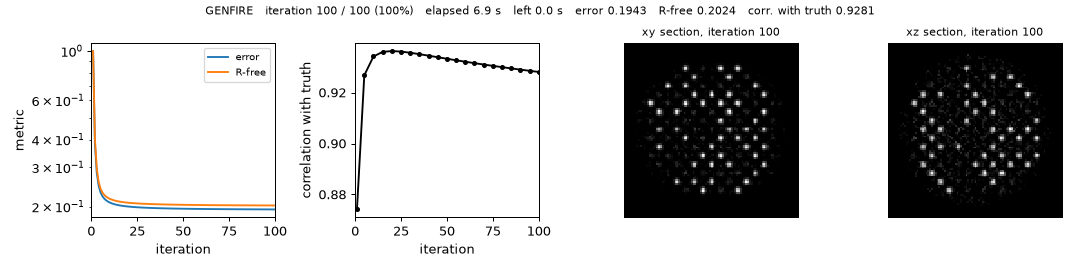

grid                 : 192^3
support              : MaskedSupport(sphere, n=192, extent=(84, 84, 84), float32, box=8.4% of grid)
FFT work after prune : 54%
iterations           : 100
final k-space error  : 0.19432
final R-free         : 0.20243
gridding             : 0.6 s
FFT planning         : 0.0 s
iteration loop       : 7.2 s  (0.07 s/iter)
total                : 7.9 s
CPU time             : 18.0 s  (2.3 cores busy)


In [5]:
truth = particle.volume()
monitor = LiveMonitor(config.num_iterations, every=5, truth=truth, title="GENFIRE")
result = gc.reconstruct(projections, euler, config, support=support, on_progress=monitor)
genfire = result.reconstruction
print(result.summary())

この例では，正解との相関係数は 20〜30 回目あたりで最大になり，その後わずかに下がります．一方，error と R-free は下がり続けます．測定値（ノイズを含む）とのずれが小さいほど正解に近いとは限らない，ということです．実験では正解がわからないので，反復回数はシミュレーションで見当をつけておきます．

In this example the correlation with the ground truth peaks at around 20–30 iterations and then drops slightly, while the error (and R-free) keeps falling: fitting the noisy data more closely does not always bring the volume closer to the truth. In experiments, where the truth is unknown, the number of iterations is chosen with the help of simulations like this one.

## 4. 結果を見る / Look at the result

中心を通る断面です．xz 断面（傾斜軸に垂直な面）では，ミッシングウェッジのため z 方向に少し伸びて見えることがあります．

Central sections. In the xz section (perpendicular to the tilt axis), features may look slightly elongated along z because of the missing wedge.

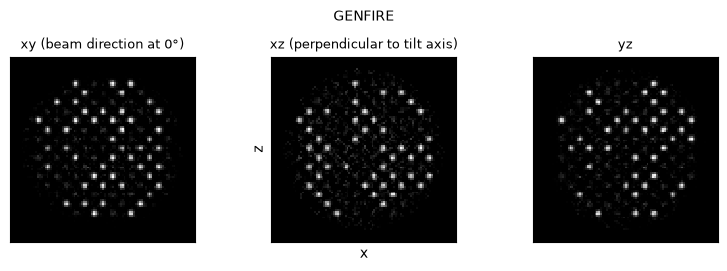

In [6]:
show_orthoslices(genfire, "GENFIRE"); plt.show()

正解と同じ断面を並べて比べます．`thickness=3` で原子 1 層ぶんを足し合わせて表示します．

Compare with the same section of the ground truth. `thickness=3` sums about one atomic layer.

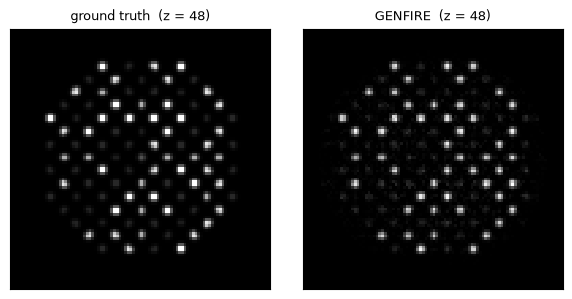

In [7]:
show_slices({"ground truth": truth, "GENFIRE": genfire}, thickness=3); plt.show()

In [8]:
np.save(DATA / "genfire.npy", genfire)
print("saved: data/genfire.npy")

saved: data/genfire.npy

### やってみよう / Try it

- `num_iterations` を 20 や 300 に変えて，誤差と像の変化を見てみましょう．
  Change `num_iterations` to 20 or 300 and watch the error and the images.
- `support=None` にするとサポートが箱全体になります．再構成はどう変わるでしょうか．
  With `support=None` the support is the whole box. How does the reconstruction change?
- 01 で `counts_per_atom` を変えて（ノイズを増やして）から，もう一度再構成してみましょう．
  Change `counts_per_atom` in 01 (more noise) and reconstruct again.
- 最初のセルで `INPUT = "tilt_series_aligned.npz"` として，02 で位置合わせしたデータを再構成してみましょう．
  Set `INPUT = "tilt_series_aligned.npz"` in the first cell to reconstruct the data aligned in 02.